# Preprocesamiento — Electricidad y Magnetismo

### Pregunta de investigación
¿Hay carreras (como Mecatrónica, con formación más eléctrica) que aprueban significativamente más que otras (como Civil)?

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)

## 1. Ruta y archivos de entrada

In [41]:
PATH = r'D:\Materiales\IA\cursoIA2026\Semana_03\Ejercicio\datos\reglamentonuevo'

files = sorted([
    f for f in os.listdir(PATH)
    if f.lower().endswith(('.xls', '.xlsx'))
])

print(f'📂 Carpeta: {PATH}')
print(f'📄 Archivos encontrados: {len(files)}\n')

for f in files:
    print(' -', f)

if not files:
    raise FileNotFoundError('No se encontraron archivos .xls/.xlsx en la carpeta indicada.')

📂 Carpeta: D:\Materiales\IA\cursoIA2026\Semana_03\Ejercicio\datos\reglamentonuevo
📄 Archivos encontrados: 3

 - rendimiento_año_2024_ciclo_2_anon.xlsx
 - rendimiento_año_2025_ciclo_1_anon.xlsx
 - rendimiento_año_2025_ciclo_2_anon.xlsx


## 2. Funciones auxiliares

In [42]:
def extraer_anho_semestre(filename):
    """Extrae año y ciclo/semestre del nombre del archivo.
    Primero busca patrones explícitos como año_2025 y ciclo_2.
    Devuelve (anho, semestre) o (None, None) si no los encuentra.
    """
    nombre = os.path.basename(filename)

    match_anho = re.search(r'(?:año|anho|ano)[_\- ]?(\d{4})', nombre, flags=re.IGNORECASE)
    if match_anho is None:
        match_anho = re.search(r'(20\d{2})', nombre)

    match_semestre = re.search(r'(?:ciclo|semestre)[_\- ]?(\d+)', nombre, flags=re.IGNORECASE)

    anho = int(match_anho.group(1)) if match_anho else None
    semestre = int(match_semestre.group(1)) if match_semestre else None

    return anho, semestre


def cargar_y_concatenar(path, archivos):
    """Carga y concatena todos los Excel de la carpeta."""
    partes = []

    for i, filename in enumerate(archivos, start=1):
        print(f'📄 Procesando {i}/{len(archivos)}: {filename}')

        try:
            lectura = pd.read_excel(
                os.path.join(path, filename),
                sheet_name='Sheet1'
            )

            anho, semestre = extraer_anho_semestre(filename)

            if anho is None or semestre is None:
                print('   ⚠️ No se pudo extraer año/semestre; se conserva el archivo con NaN en esas columnas.')

            lectura['Anho'] = anho
            lectura['Semestre'] = semestre
            lectura['Archivo_Origen'] = filename

            partes.append(lectura)
            print(f'   ✅ {len(lectura):,} registros')

        except Exception as e:
            print(f'   ❌ Error: {e}')

    if not partes:
        raise ValueError('No se pudo cargar ningún archivo.')

    return pd.concat(partes, ignore_index=True)

## 3. Carga y concatenación

In [43]:
datos = cargar_y_concatenar(PATH, files)

print('\n' + '=' * 80)
print('DATASET CONCATENADO')
print('=' * 80)
print(f'Registros: {len(datos):,}')
print(f'Columnas: {len(datos.columns)}')

display(datos.head())

📄 Procesando 1/3: rendimiento_año_2024_ciclo_2_anon.xlsx
   ✅ 24,468 registros
📄 Procesando 2/3: rendimiento_año_2025_ciclo_1_anon.xlsx
   ✅ 19,407 registros
📄 Procesando 3/3: rendimiento_año_2025_ciclo_2_anon.xlsx
   ✅ 20,420 registros

DATASET CONCATENADO
Registros: 64,295
Columnas: 30


,ALUMNO_ID,Cod.Asign,Asignatura,Cod.Car.Sec,Cod.Curso,Convocatoria,Anho,Semestre,Doc.Firma,Aprobado,Anho.Firma,Primer.Par,Segundo.Par,Tercer.Par,TPLab.,Lab.,Proy.,Pond.PP,Pond.SP,Pond.TPLab,Pond.Lab,Pond.Proy,Asis,Requisito,Firma,Primer.Rec,Segundo.Rec,Nota.Final,Archivo_Origen,FirmaCalculada
0,FIUNA_ALUMNO_005925,13012,FISICA 3,CGF-PLS13,3,2,2024,2,0,N,0,33,43,0,40,100,0,40,40,10,10,0,1,1,0.0,28,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN
1,FIUNA_ALUMNO_007516,13012,FISICA 3,CGF-PLS13,3,2,2024,2,0,N,0,33,43,0,40,100,0,40,40,10,10,0,1,1,0.0,28,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN
2,FIUNA_ALUMNO_005493,13012,FISICA 3,ELE-PLS13,3,2,2024,2,0,N,0,5,10,0,20,80,0,40,40,10,10,0,1,0,0.0,0,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN
3,FIUNA_ALUMNO_007517,13012,FISICA 3,ELE-PLS13,3,2,2024,2,0,N,0,5,10,0,20,80,0,40,40,10,10,0,1,0,0.0,0,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN
4,FIUNA_ALUMNO_006375,13012,FISICA 3,CIV-PLS13,3,2,2024,2,0,N,0,30,30,0,50,100,0,40,40,10,10,0,1,1,0.0,14,0,NaN,rendimiento_año_2024_ciclo_2_anon.xlsx,NaN


## 4. Construcción de la variable `Carrera`

In [44]:
if 'Cod.Car.Sec' not in datos.columns:
    raise KeyError("No existe la columna 'Cod.Car.Sec'.")

datos['Carrera'] = (
    datos['Cod.Car.Sec']
    .astype(str)
    .str.strip()
    .str.split('-')
    .str[0]
)

print(f"🎓 Carreras únicas: {datos['Carrera'].nunique()}")
display(datos['Carrera'].value_counts())

🎓 Carreras únicas: 20


Carrera
CIV           26879
ELE           11290
MCT            6771
IND            6045
CGF            4538
MEC            2340
INT9CONSTR     1861
ECA            1641
INT9MECANI      522
INT9ELECTR      506
MCT9            376
INT9TRANSP      344
INT9G           235
MEC9            231
INT9ORTERR      214
INT9            136
INT9SDIGYT      132
INT9SANEHI       94
INT9RNYMA        88
ECA9             52
Name: count, dtype: int64

## 5. Guardar dataset concatenado

In [45]:
archivo_concatenado = os.path.join(PATH, 'datos_concatenados_EyM.csv')

datos.to_csv(
    archivo_concatenado,
    index=False,
    encoding='utf-8-sig'
)

print(f'✅ Guardado en: {archivo_concatenado}')

✅ Guardado en: D:\Materiales\IA\cursoIA2026\Semana_03\Ejercicio\datos\reglamentonuevo\datos_concatenados_EyM.csv


## 6. Revisar nombres de asignaturas

In [46]:
asignaturas = (
    datos['Asignatura']
    .astype(str)
    .str.strip()
    .value_counts()
)

display(asignaturas)

Asignatura
CALCULO 1                   1907
ESTATICA                    1798
GEOMETRIA DESCRIPTIVA       1670
MECANICA DE MATERIALES 1    1646
ALGEBRA LINEAL              1536
                            ... 
CALCULO 3                      6
SISTEMA DE REDES 1             6
SISTEMAS DE TELEFONIA 2        4
FOTOGRAMETRIA I                4
LENGUAJE DE PROGRAMACION       2
Name: count, Length: 325, dtype: int64

## 7. Filtrar **Electricidad y Magnetismo**

In [47]:
datos['Asignatura_limpia'] = (
    datos['Asignatura']
    .astype(str)
    .str.strip()
    .str.upper()
)

filtro_em = (
    datos['Asignatura_limpia'].str.contains('ELECTRICIDAD', na=False)
    & datos['Asignatura_limpia'].str.contains('MAGNETISMO', na=False)
)

datos_em = datos.loc[filtro_em].copy()

print(f'✅ Registros encontrados: {len(datos_em):,}')
print('\nNombres exactos encontrados:')
display(datos_em['Asignatura'].value_counts())

if datos_em.empty:
    raise ValueError('No se encontró ninguna asignatura que contenga ELECTRICIDAD y MAGNETISMO.')

✅ Registros encontrados: 1,515

Nombres exactos encontrados:


Asignatura
ELECTRICIDAD Y MAGNETISMO    1515
Name: count, dtype: int64

## 8. Limpieza de `Nota.Final` y `Aprobado`

In [48]:
if 'Nota.Final' in datos_em.columns:
    datos_em['Nota.Final'] = (
        datos_em['Nota.Final']
        .astype(str)
        .str.strip()
        .str.replace(',', '.', regex=False)
    )
    datos_em['Nota.Final'] = pd.to_numeric(
        datos_em['Nota.Final'],
        errors='coerce'
    )

if 'Aprobado' not in datos_em.columns:
    raise KeyError("No existe la columna 'Aprobado'.")

datos_em['Aprobado'] = (
    datos_em['Aprobado']
    .astype(str)
    .str.strip()
    .str.upper()
)

datos_em['Aprobado_binario'] = (
    datos_em['Aprobado'] == 'S'
).astype(int)

print('Valores de Aprobado:')
display(datos_em['Aprobado'].value_counts(dropna=False))

if 'Nota.Final' in datos_em.columns:
    print('\nResumen de Nota.Final:')
    display(datos_em['Nota.Final'].describe())

Valores de Aprobado:


Aprobado
N    1195
S     320
Name: count, dtype: int64


Resumen de Nota.Final:


count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Nota.Final, dtype: float64

## 9. Tamaño, faltantes y duplicados

📌 Registros: 1,515
📌 Estudiantes únicos: 1,246
📌 Carreras únicas: 7
📌 Duplicados exactos: 0
Tipos de variables:


int64      23
str         6
float64     3
object      1
Name: count, dtype: int64

,Tipo
ALUMNO_ID,str
Cod.Asign,int64
Asignatura,str
Cod.Car.Sec,str
Cod.Curso,int64
Convocatoria,int64
Anho,int64
Semestre,int64
Doc.Firma,int64
Aprobado,str



Datos faltantes:


,Faltantes
Nota.Final,1515
FirmaCalculada,1515


,Primer.Par,Segundo.Par,Lab.,Asis,Firma
count,1515.000000,1515.000000,1515.000000,1515.000000,1515.000000
mean,28.421122,23.168317,91.591419,1.033003,26.650165
std,21.670666,24.734683,17.933130,0.381499,24.718903
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,10.000000,0.000000,92.000000,1.000000,0.000000
50%,27.000000,17.000000,98.000000,1.000000,19.000000
75%,44.000000,43.000000,100.000000,1.000000,50.000000
max,98.000000,98.000000,100.000000,2.000000,98.000000


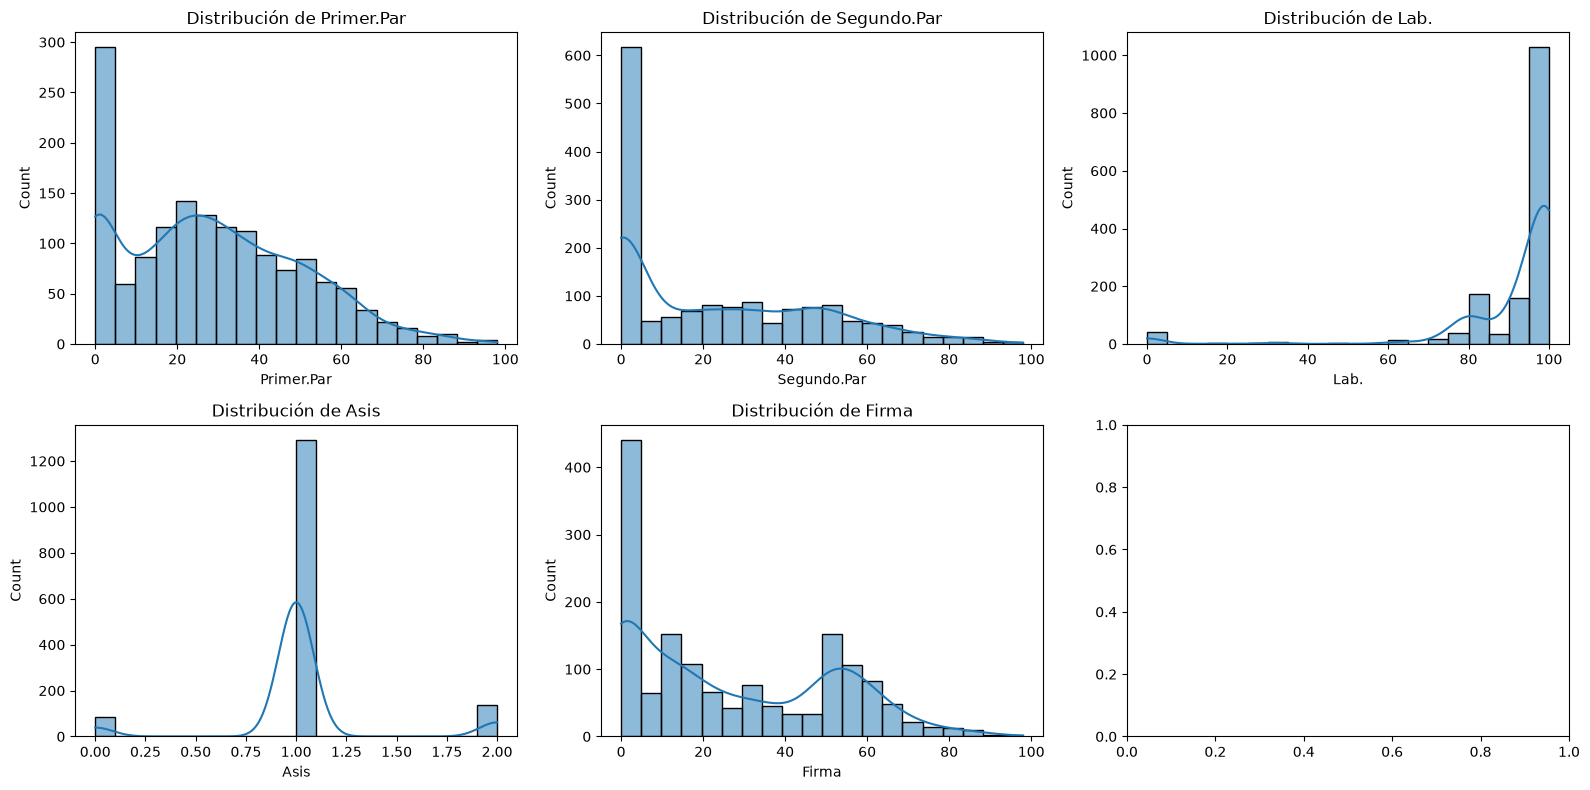

In [49]:
print(f'📌 Registros: {len(datos_em):,}')
print(f"📌 Estudiantes únicos: {datos_em['ALUMNO_ID'].nunique():,}")
print(f"📌 Carreras únicas: {datos_em['Carrera'].nunique():,}")
print(f"📌 Duplicados exactos: {datos_em.duplicated().sum():,}")
print("Tipos de variables:")
display(datos_em.dtypes.value_counts())
display(datos_em.dtypes.to_frame("Tipo"))

print('\nDatos faltantes:')
display(
    datos_em.isna().sum()
    .sort_values(ascending=False)
    .to_frame('Faltantes')
    .query('Faltantes > 0')
)

variables_numericas = ["Primer.Par", "Segundo.Par", "Lab.", "Asis", "Firma"]
display(datos_em[variables_numericas].describe())

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, variables_numericas):
    sns.histplot(datos_em[col], bins=20, ax=ax, kde=True)
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

**Interpretación:** el Segundo Parcial tiene mediana 17 (más bajo que el Primer Parcial, 
mediana 27), lo que sugiere que el segundo parcial es más difícil o los alumnos llegan con 
menos preparación. La asistencia (`Asis`) está casi siempre en 1 (obligatoria/cumplida), 
por lo que aporta poca variabilidad como predictor. `Firma` tiene alta dispersión (std=24.7) 
y mediana baja (19), reflejando que la mayoría de los alumnos no llega a cumplir el 
requisito de regularidad completo.

## 10. Tasa de aprobación general

In [50]:
total = len(datos_em)
aprobados = int(datos_em['Aprobado_binario'].sum())
no_aprobados = total - aprobados
tasa = aprobados / total * 100

print(f'Total: {total:,}')
print(f'Aprobados: {aprobados:,}')
print(f'No aprobados: {no_aprobados:,}')
print(f'Tasa de aprobación: {tasa:.2f}%')

Total: 1,515
Aprobados: 320
No aprobados: 1,195
Tasa de aprobación: 21.12%


## 11. Tasa de aprobación por carrera

In [51]:
aprobacion_carrera = (
    datos_em
    .groupby('Carrera', dropna=False)
    .agg(
        Total=('Aprobado_binario', 'size'),
        Aprobados=('Aprobado_binario', 'sum'),
        Tasa_Aprobacion=('Aprobado_binario', 'mean')
    )
    .reset_index()
)

aprobacion_carrera['No_Aprobados'] = (
    aprobacion_carrera['Total'] - aprobacion_carrera['Aprobados']
)

aprobacion_carrera['Tasa_Aprobacion'] *= 100

aprobacion_carrera = aprobacion_carrera.sort_values(
    'Tasa_Aprobacion', ascending=False
)

display(aprobacion_carrera)

,Carrera,Total,Aprobados,Tasa_Aprobacion,No_Aprobados
2,ECA,46,16,34.782609,30
5,MCT,170,48,28.235294,122
4,IND,152,34,22.368421,118
1,CIV,715,154,21.538462,561
3,ELE,290,60,20.689655,230
6,MEC,68,4,5.882353,64
0,CGF,74,4,5.405405,70


## 12. Aprobación por carrera y año

In [52]:
if {'Anho', 'Carrera'}.issubset(datos_em.columns):
    aprobacion_carrera_anho = (
        datos_em
        .groupby(['Anho', 'Carrera'], dropna=False)
        .agg(
            Total=('Aprobado_binario', 'size'),
            Aprobados=('Aprobado_binario', 'sum'),
            Tasa_Aprobacion=('Aprobado_binario', 'mean')
        )
        .reset_index()
    )

    aprobacion_carrera_anho['Tasa_Aprobacion'] *= 100
    display(
        aprobacion_carrera_anho.sort_values(
            ['Anho', 'Tasa_Aprobacion'],
            ascending=[True, False]
        )
    )

,Anho,Carrera,Total,Aprobados,Tasa_Aprobacion
2,2024,ECA,16,4,25.000000
5,2024,MCT,76,16,21.052632
4,2024,IND,58,12,20.689655
1,2024,CIV,285,50,17.543860
3,2024,ELE,98,14,14.285714
0,2024,CGF,30,2,6.666667
6,2024,MEC,38,2,5.263158
9,2025,ECA,30,12,40.000000
12,2025,MCT,94,32,34.042553
8,2025,CIV,430,104,24.186047


## 13. Aprobación por carrera y semestre

In [53]:
if {'Semestre', 'Carrera'}.issubset(datos_em.columns):
    aprobacion_carrera_semestre = (
        datos_em
        .groupby(['Carrera', 'Semestre'], dropna=False)
        .agg(
            Total=('Aprobado_binario', 'size'),
            Aprobados=('Aprobado_binario', 'sum'),
            Tasa_Aprobacion=('Aprobado_binario', 'mean')
        )
        .reset_index()
    )

    aprobacion_carrera_semestre['Tasa_Aprobacion'] *= 100
    display(
        aprobacion_carrera_semestre.sort_values(
            ['Carrera', 'Semestre']
        )
    )

,Carrera,Semestre,Total,Aprobados,Tasa_Aprobacion
0,CGF,2,74,4,5.405405
1,CIV,2,715,154,21.538462
2,ECA,2,46,16,34.782609
3,ELE,2,290,60,20.689655
4,IND,2,152,34,22.368421
5,MCT,2,170,48,28.235294
6,MEC,2,68,4,5.882353


## 14. Visualización: tasa de aprobación por carrera

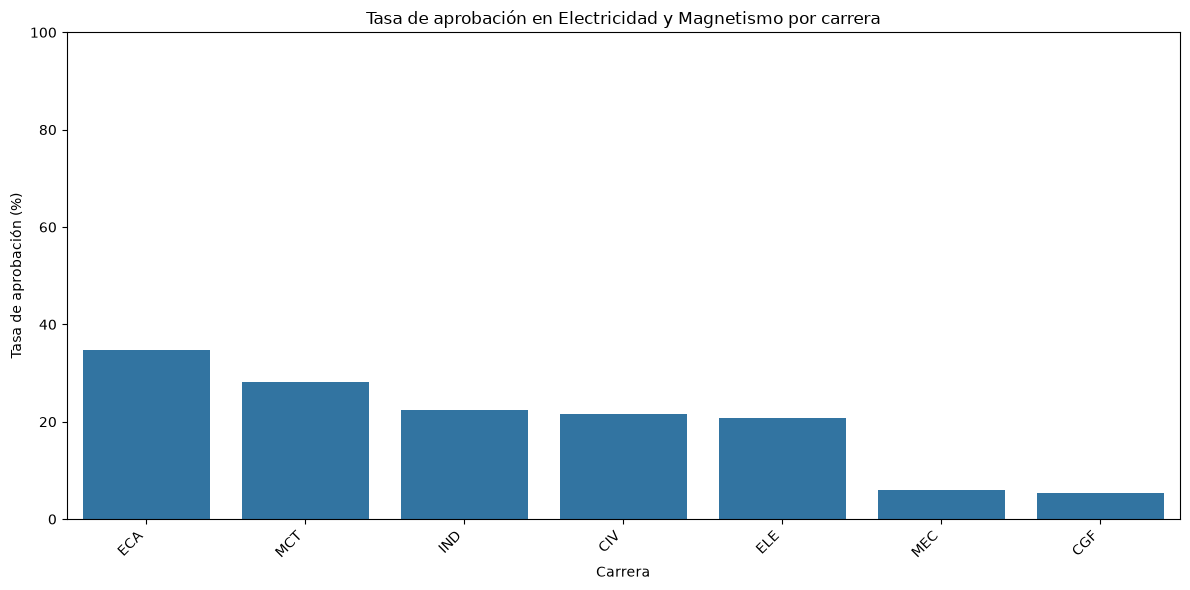

In [54]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=aprobacion_carrera,
    x='Carrera',
    y='Tasa_Aprobacion'
)
plt.title('Tasa de aprobación en Electricidad y Magnetismo por carrera')
plt.xlabel('Carrera')
plt.ylabel('Tasa de aprobación (%)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 15. Guardar dataset final

Se conserva la información necesaria para el análisis posterior. `Aprobado_binario` será la variable objetivo (`y`) de los modelos.

In [55]:
archivo_final = os.path.join(
    PATH,
    "datos_electricidad_magnetismo.csv"
)

# Guardar todas las columnas disponibles de Electricidad y Magnetismo
datos_electricidad_magnetismo = datos_em.copy()

datos_electricidad_magnetismo.to_csv(
    archivo_final,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 80)
print("✅ PREPROCESAMIENTO COMPLETADO")
print("=" * 80)

print(
    f"Registros finales: "
    f"{len(datos_electricidad_magnetismo):,}"
)

print(
    f"Columnas finales: "
    f"{len(datos_electricidad_magnetismo.columns)}"
)

print(
    f"Archivo: "
    f"{archivo_final}"
)

print("\nColumnas finales:")
print(
    datos_electricidad_magnetismo.columns.tolist()
)
print('=' * 80)
print(f'Registros finales: {len(datos_electricidad_magnetismo):,}')
print(f'Archivo: {archivo_final}')
print('\nColumnas finales:')
print(datos_electricidad_magnetismo.columns.tolist())

✅ PREPROCESAMIENTO COMPLETADO
Registros finales: 1,515
Columnas finales: 33
Archivo: D:\Materiales\IA\cursoIA2026\Semana_03\Ejercicio\datos\reglamentonuevo\datos_electricidad_magnetismo.csv

Columnas finales:
['ALUMNO_ID', 'Cod.Asign', 'Asignatura', 'Cod.Car.Sec', 'Cod.Curso', 'Convocatoria', 'Anho', 'Semestre', 'Doc.Firma', 'Aprobado', 'Anho.Firma', 'Primer.Par', 'Segundo.Par', 'Tercer.Par', 'TPLab.', 'Lab.', 'Proy.', 'Pond.PP', 'Pond.SP', 'Pond.TPLab', 'Pond.Lab', 'Pond.Proy', 'Asis', 'Requisito', 'Firma', 'Primer.Rec', 'Segundo.Rec', 'Nota.Final', 'Archivo_Origen', 'FirmaCalculada', 'Carrera', 'Asignatura_limpia', 'Aprobado_binario']
Registros finales: 1,515
Archivo: D:\Materiales\IA\cursoIA2026\Semana_03\Ejercicio\datos\reglamentonuevo\datos_electricidad_magnetismo.csv

Columnas finales:
['ALUMNO_ID', 'Cod.Asign', 'Asignatura', 'Cod.Car.Sec', 'Cod.Curso', 'Convocatoria', 'Anho', 'Semestre', 'Doc.Firma', 'Aprobado', 'Anho.Firma', 'Primer.Par', 'Segundo.Par', 'Tercer.Par', 'TPLab.', 